<a href="https://colab.research.google.com/github/withrishab/hcl-project/blob/main/AUTOMATION_PROJECT_HCL(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Load the Dataset
We will load the `imports-85.data` file. Since it doesn't contain a header, we will define the column names according to the standard UCI Machine Learning Repository Automobile dataset schema.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Columns schema for imports-85.data
columns = [
    'symboling', 'normalized-losses', 'make', 'fuel-type', 'aspiration',
    'num-of-doors', 'body-style', 'drive-wheels', 'engine-location',
    'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-type',
    'num-of-cylinders', 'engine-size', 'fuel-system', 'bore', 'stroke',
    'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price'
]

# Read dataset and replace '?' with NaN
df = pd.read_csv('/content/imports-85.data', names=columns, na_values='?')

# Display basic information
print("Shape:", df.shape)
print("\n--- Head ---")
display(df.head())
print("\n--- Tail ---")
display(df.tail())
print("\n--- Info ---")
df.info()
print("\n--- Describe ---")
display(df.describe(include='all'))

Shape: (205, 26)

--- Head ---


,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0



--- Tail ---


,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
200,-1,95.0,volvo,gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114.0,5400.0,23,28,16845.0
201,-1,95.0,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160.0,5300.0,19,25,19045.0
202,-1,95.0,volvo,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134.0,5500.0,18,23,21485.0
203,-1,95.0,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.40,23.0,106.0,4800.0,26,27,22470.0
204,-1,95.0,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114.0,5400.0,19,25,22625.0



--- Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized-losses  164 non-null    float64
 2   make               205 non-null    object 
 3   fuel-type          205 non-null    object 
 4   aspiration         205 non-null    object 
 5   num-of-doors       203 non-null    object 
 6   body-style         205 non-null    object 
 7   drive-wheels       205 non-null    object 
 8   engine-location    205 non-null    object 
 9   wheel-base         205 non-null    float64
 10  length             205 non-null    float64
 11  width              205 non-null    float64
 12  height             205 non-null    float64
 13  curb-weight        205 non-null    int64  
 14  engine-type        205 non-null    object 
 15  num-of-cylinders   205 non-null    object 
 16  engine-size 

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
count,205.000000,164.000000,205,205,205,203,205,205,205,205.000000,...,205.000000,205,201.000000,201.000000,205.000000,203.000000,203.000000,205.000000,205.000000,201.000000
unique,NaN,NaN,22,2,2,2,5,3,2,NaN,...,NaN,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,toyota,gas,std,four,sedan,fwd,front,NaN,...,NaN,mpfi,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,32,185,168,114,96,120,202,NaN,...,NaN,94,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,0.834146,122.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,98.756585,...,126.907317,NaN,3.329751,3.255423,10.142537,104.256158,5125.369458,25.219512,30.751220,13207.129353
std,1.245307,35.442168,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.021776,...,41.642693,NaN,0.273539,0.316717,3.972040,39.714369,479.334560,6.542142,6.886443,7947.066342
min,-2.000000,65.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,86.600000,...,61.000000,NaN,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,0.000000,94.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,94.500000,...,97.000000,NaN,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7775.000000
50%,1.000000,115.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,97.000000,...,120.000000,NaN,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,2.000000,150.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,102.400000,...,141.000000,NaN,3.590000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16500.000000


### 2. Missing Values, Duplicates, and Data Processing

In [ ]:
# Check for duplicates
duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates}")

# Convert price and horsepower columns to numeric (handling NaNs)
df['price'] = pd.to_numeric(df['price'])
df['horsepower'] = pd.to_numeric(df['horsepower'])

# Identify columns with missing values
missing_counts = df.isnull().sum()
print("\nColumns with missing values and counts:")
print(missing_counts[missing_counts > 0])

Number of duplicate rows: 0

Columns with missing values and counts:
normalized-losses    41
num-of-doors          2
bore                  4
stroke                4
horsepower            2
peak-rpm              2
price                 4
dtype: int64


### 3. Exploratory Data Analysis & Answering the Questions

- (1) Which car manufacturers appear most often?
- (2) What are the average, minimum, and maximum car prices?
- (3) Which body style has the highest average price?
- (4) Compare average engine size across fuel types.
- (5) Identify columns with missing values and count them (handled above, but summarized here).
- (6) List the 10 most expensive cars.

In [ ]:
# (1) Top manufacturers
print("--- Top 5 Manufacturers ---")
print(df['make'].value_counts().head())

# (2) Price stats using NumPy array on non-null price data
prices_array = df['price'].dropna().to_numpy()
avg_price = np.mean(prices_array)
min_price = np.min(prices_array)
max_price = np.max(prices_array)
print(f"\n--- Price Statistics ---\nAverage Price: ${avg_price:.2f}\nMinimum Price: ${min_price:.2f}\nMaximum Price: ${max_price:.2f}")

# (3) Body style with highest average price
print("\n--- Average Price by Body Style ---")
body_style_prices = df.groupby('body-style')['price'].mean().sort_values(ascending=False)
display(body_style_prices)

# (4) Compare average engine size across fuel types
print("\n--- Average Engine Size by Fuel Type ---")
fuel_engine_size = df.groupby('fuel-type')['engine-size'].mean()
display(fuel_engine_size)

# (6) 10 most expensive cars
print("\n--- 10 Most Expensive Cars ---")
display(df[['make', 'body-style', 'engine-size', 'horsepower', 'price']].sort_values(by='price', ascending=False).head(10))

--- Top 5 Manufacturers ---
make
toyota        32
nissan        18
mazda         17
mitsubishi    13
honda         13
Name: count, dtype: int64

--- Price Statistics ---
Average Price: $13207.13
Minimum Price: $5118.00
Maximum Price: $45400.00

--- Average Price by Body Style ---


,price
body-style,
hardtop,22208.500000
convertible,21890.500000
sedan,14459.755319
wagon,12371.960000
hatchback,9957.441176



--- Average Engine Size by Fuel Type ---


,engine-size
fuel-type,
diesel,135.700000
gas,125.956757



--- 10 Most Expensive Cars ---


,make,body-style,engine-size,horsepower,price
74,mercedes-benz,hardtop,304,184.0,45400.0
16,bmw,sedan,209,182.0,41315.0
73,mercedes-benz,sedan,308,184.0,40960.0
128,porsche,convertible,194,207.0,37028.0
17,bmw,sedan,209,182.0,36880.0
49,jaguar,sedan,326,262.0,36000.0
48,jaguar,sedan,258,176.0,35550.0
72,mercedes-benz,convertible,234,155.0,35056.0
71,mercedes-benz,sedan,234,155.0,34184.0
127,porsche,hardtop,194,207.0,34028.0


### 4. Data Visualizations

/tmp/ipykernel_3501/976875499.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='make', order=df['make'].value_counts().index, palette='viridis')


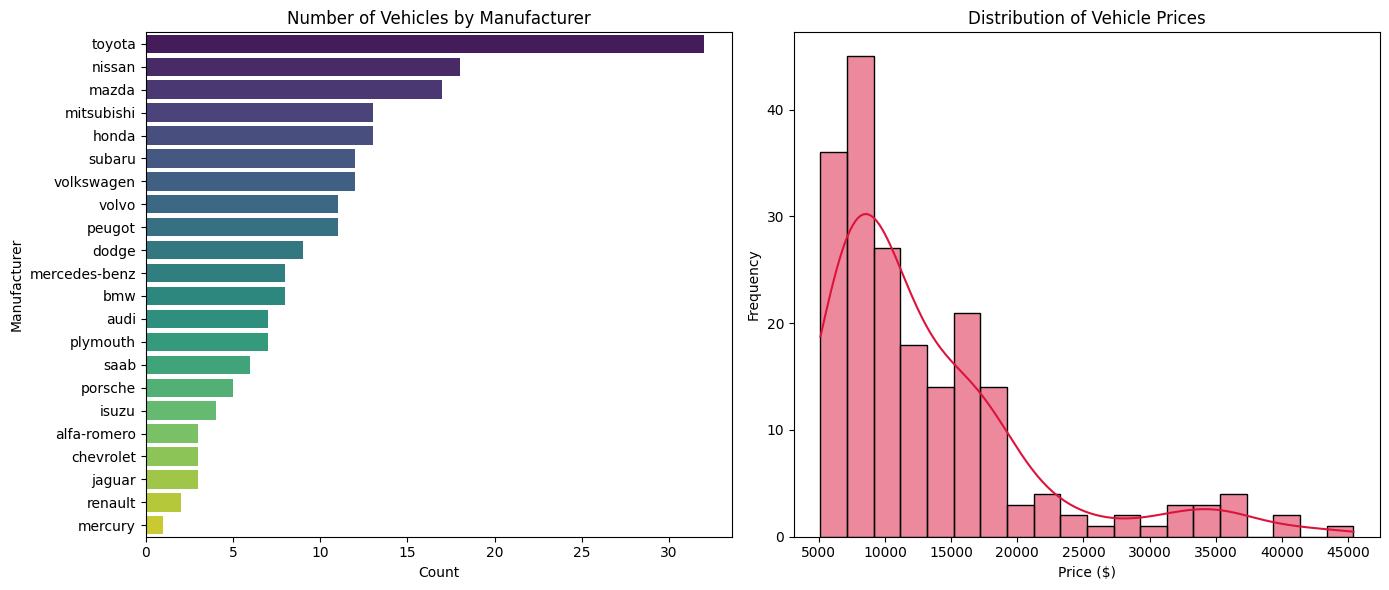

In [ ]:
plt.figure(figsize=(14, 6))

# Chart 1: Manufacturer Counts
plt.subplot(1, 2, 1)
sns.countplot(data=df, y='make', order=df['make'].value_counts().index, palette='viridis')
plt.title('Number of Vehicles by Manufacturer')
plt.xlabel('Count')
plt.ylabel('Manufacturer')

# Chart 2: Price Distribution Histogram
plt.subplot(1, 2, 2)
sns.histplot(df['price'].dropna(), bins=20, kde=True, color='crimson')
plt.title('Distribution of Vehicle Prices')
plt.xlabel('Price ($)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

### 5. Observations
1. **Market Dominance**: Toyota is the most highly represented manufacturer in this dataset by a wide margin, followed by Nissan and Mazda.
2. **Price Distribution**: Car prices are heavily right-skewed; most cars are relatively affordable (priced under $15,000), while a small selection of luxury imports drives up the maximum price to $45,400.
3. **Luxury & Design Body Styles**: Hardtops and convertibles command the highest average prices compared to hatchbacks, sedans, and wagons. In addition, diesel-powered vehicles show a slightly larger average engine size than gas-powered ones.